In [1]:
# cella 1 — le importazioni e il dato
import matplotlib.pyplot as plt
import pandas as pd

from campagne.caricamento import carica, colonne_per_tipo

dati = carica()
dati.shape


Matplotlib is building the font cache; this may take a moment.


(41188, 21)

In [2]:
# cella 2 — le prime righe, e i nomi delle colonne
dati.head()


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# cella 3 — che cosa c'è in ogni colonna
dati.info()


<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [6]:
# cella 4 — l'etichetta
dati["y"].value_counts()


y
no     36548
yes     4640
Name: count, dtype: int64

In [7]:
# cella 5 — la stessa cosa in quota
dati["y"].value_counts(normalize=True)


y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

In [8]:
# cella 6 — i numeri, uno sguardo d'insieme
numeriche, testuali = colonne_per_tipo(dati)
dati[numeriche].describe().T.round(2)


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [9]:
# cella 7 — il sintomo, guardato da vicino
dati["pdays"].value_counts().head()


pdays
999    39673
3        439
6        412
4        118
9         64
Name: count, dtype: int64

In [10]:
# cella 8 — quanto cambia togliendo il codice
veri = dati.loc[dati["pdays"] != 999, "pdays"]
print(f"media con la sentinella dentro: {dati['pdays'].mean():.1f}")
print(f"media sulle righe vere:         {veri.mean():.1f}  (mediana {veri.median():.0f}, massimo {veri.max():.0f})")


media con la sentinella dentro: 962.5
media sulle righe vere:         6.0  (mediana 6, massimo 27)


In [11]:
# cella 9 — i mancanti che pandas non vede
for colonna in testuali:
    quanti = (dati[colonna] == "unknown").sum()
    if quanti:
        print(f"{colonna:12s} {quanti:6d}  {quanti / len(dati):6.2%}")


job             330   0.80%
marital          80   0.19%
education      1731   4.20%
default        8597  20.87%
housing         990   2.40%
loan            990   2.40%


In [12]:
# cella 10 — quanto costerebbe cancellarle
ha_un_mancante = (dati[testuali] == "unknown").any(axis=1)
print(f"righe con almeno un unknown: {ha_un_mancante.sum()} = {ha_un_mancante.mean():.2%}")
print(f"quota di sì fra queste righe: {dati.loc[ha_un_mancante, 'y'].eq('yes').mean():.2%}")
print(f"quota di sì fra le altre:     {dati.loc[~ha_un_mancante, 'y'].eq('yes').mean():.2%}")


righe con almeno un unknown: 10700 = 25.98%
quota di sì fra queste righe: 7.30%
quota di sì fra le altre:     12.66%


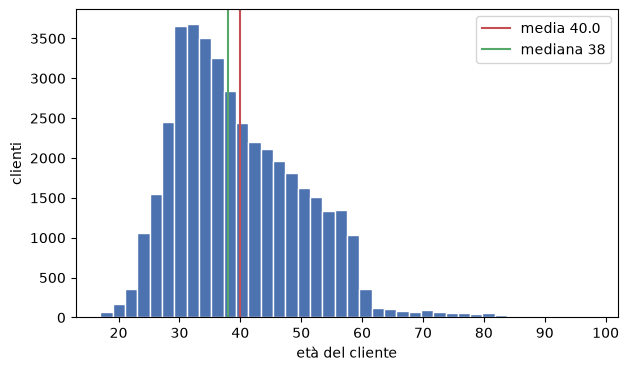

In [13]:
# cella 11 — l'età, guardata invece che riassunta
figura, assi = plt.subplots(figsize=(7, 4))
assi.hist(dati["age"], bins=40, color="#4c72b0", edgecolor="white")
assi.axvline(dati["age"].mean(), color="#c44e52", label=f"media {dati['age'].mean():.1f}")
assi.axvline(dati["age"].median(), color="#55a868", label=f"mediana {dati['age'].median():.0f}")
assi.set_xlabel("età del cliente")
assi.set_ylabel("clienti")
assi.legend()


In [14]:
# cella 12 — chi sottoscrive, per professione
(dati.groupby("job")["y"].apply(lambda colonna: colonna.eq("yes").mean()) * 100).round(2).sort_values(ascending=False)


job
student          31.43
retired          25.23
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.89
Name: y, dtype: float64

In [15]:
# cella 13 — il tempo, che nel file non ha una data
dati["month"].value_counts()


month
may    13769
jul     7174
aug     6178
jun     5318
nov     4101
apr     2632
oct      718
sep      570
mar      546
dec      182
Name: count, dtype: int64

In [16]:
# cella 14 — il mondo che cambia lungo il file
fette = pd.qcut(pd.Series(range(len(dati))), 10, labels=False)
tabella = dati.groupby(fette)[["euribor3m", "emp.var.rate", "nr.employed"]].mean()
tabella["quota_si"] = dati.groupby(fette)["y"].apply(lambda colonna: colonna.eq("yes").mean())
tabella.round(3)


,euribor3m,emp.var.rate,nr.employed,quota_si
0,4.857,1.100,5191.000,0.028
1,4.859,1.135,5195.278,0.035
2,4.941,1.400,5228.100,0.042
3,4.961,1.400,5228.100,0.066
4,4.965,1.400,5228.100,0.062
5,4.845,1.139,5222.485,0.055
6,3.370,-0.571,5168.959,0.102
7,1.354,-1.800,5099.100,0.120
8,1.260,-2.026,5094.402,0.157
9,0.802,-2.358,5014.849,0.459


In [17]:
# cella 15 — la colonna che non useremo mai
dati.groupby("y")["duration"].mean().round(1)


y
no     220.8
yes    553.2
Name: duration, dtype: float64